In [8]:
import pandas as pd
import numpy as np

# Load sentence-level predictions
df = pd.read_csv(
    "/Users/divyajyoti/dev/grad/NLP/ANLP-ESG/data/processed/all_corpus_sentences_with_ced.csv"
)

# Map integer predictions → string labels
if "pred_label" not in df.columns and "pred_label_id" in df.columns:
    id2label = {0: "CLAIM", 1: "EVIDENCE", 2: "OTHER"}
    df["pred_label"] = df["pred_label_id"].map(id2label)

df["pred_label"] = df["pred_label"].str.upper()

# Ensure sentences are ordered correctly (IMPORTANT)
df = df.sort_values(
    ["company", "report_name", "year", "page", "sentence_id"]
).reset_index(drop=True)

df.head()


,row_id,company,report_name,year,page,sentence_id,sentence_text,pred_label_id,pred_label,pred_conf
0,29283,amazon,report_2018.pdf,2018,4,0,"On 19 September 2019, Amazon and Global Optimi...",0,CLAIM,0.429028
1,29284,amazon,report_2018.pdf,2018,4,1,Amazon is the first signatory of this pledge.,0,CLAIM,0.399390
2,29285,amazon,report_2018.pdf,2018,4,2,The Climate Pledge calls on signatories to be ...,0,CLAIM,0.513186
3,29286,amazon,report_2018.pdf,2018,4,3,Companies that sign The Climate Pledge agree t...,0,CLAIM,0.530971
4,29287,amazon,report_2018.pdf,2018,4,4,By joining The Climate Pledge and agreeing to ...,0,CLAIM,0.545754


In [9]:
def compute_page_metrics(df_page):
    """
    df_page = all sentences from one (company, report, year, page)
    """
    n_total = len(df_page)
    if n_total == 0:
        return pd.Series({
            "n_total": 0,
            "n_claim": 0,
            "n_evidence": 0,
            "claim_density": 0.0,
            "evidence_density": 0.0,
            "evidence_proximity": 0.0,
            "CED_page": 0.0
        })

    # Sentence counts
    n_claim = (df_page["pred_label"] == "CLAIM").sum()
    n_evidence = (df_page["pred_label"] == "EVIDENCE").sum()
    claim_density = n_claim / n_total
    evidence_density = n_evidence / n_total

    # ---- Evidence proximity ----
    if n_claim == 0:
        evidence_prox = 0.0
    else:
        claim_idx = df_page.loc[df_page["pred_label"] == "CLAIM", "sentence_id"].tolist()
        evidence_idx = df_page.loc[df_page["pred_label"] == "EVIDENCE", "sentence_id"].tolist()

        if len(evidence_idx) == 0:
            evidence_prox = 0.0
        else:
            prox_list = []
            for c in claim_idx:
                d = min(abs(c - e) for e in evidence_idx)
                prox_list.append(1 / (1 + d))   # proximity formula

            evidence_prox = float(np.mean(prox_list))

    # ---- Page-level CED ----
    CED_page = claim_density * (1 - evidence_prox)

    return pd.Series({
        "n_total": n_total,
        "n_claim": n_claim,
        "n_evidence": n_evidence,
        "claim_density": claim_density,
        "evidence_density": evidence_density,
        "evidence_proximity": evidence_prox,
        "CED_page": CED_page
    })

# Compute page metrics
page_stats = (
    df.groupby(["company", "report_name", "year", "page"])
      .apply(compute_page_metrics)
      .reset_index()
)

page_stats.head()


/var/folders/x1/zt0ds_657j59q2tdfjb_lm640000gn/T/ipykernel_12289/2839460583.py:56: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  .apply(compute_page_metrics)


,company,report_name,year,page,n_total,n_claim,n_evidence,claim_density,evidence_density,evidence_proximity,CED_page
0,amazon,report_2018.pdf,2018,4,6.0,6.0,0.0,1.000000,0.000000,0.000000,1.000000
1,amazon,report_2018.pdf,2018,5,6.0,4.0,2.0,0.666667,0.333333,0.320833,0.452778
2,amazon,report_2018.pdf,2018,6,1.0,0.0,1.0,0.000000,1.000000,0.000000,0.000000
3,amazon,report_2018.pdf,2018,9,6.0,3.0,3.0,0.500000,0.500000,0.444444,0.277778
4,amazon,report_2018.pdf,2018,10,2.0,1.0,1.0,0.500000,0.500000,0.500000,0.250000


In [10]:
def compute_doc_metrics(df_doc):
    """
    df_doc = all pages from one (company, report, year)
    """
    return pd.Series({
        "mean_claim_density": df_doc["claim_density"].mean(),
        "mean_evidence_density": df_doc["evidence_density"].mean(),
        "mean_CED_page": df_doc["CED_page"].mean(),
        "p90_CED_page": df_doc["CED_page"].quantile(0.90),
        "n_pages": len(df_doc)
    })

doc_stats = (
    page_stats
    .groupby(["company", "report_name", "year"])
    .apply(compute_doc_metrics)
    .reset_index()
)

doc_stats.head()


/var/folders/x1/zt0ds_657j59q2tdfjb_lm640000gn/T/ipykernel_12289/2823388588.py:16: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  .apply(compute_doc_metrics)


,company,report_name,year,mean_claim_density,mean_evidence_density,mean_CED_page,p90_CED_page,n_pages
0,amazon,report_2018.pdf,2018,0.755703,0.222889,0.600595,1.0,60.0
1,amazon,report_2019.pdf,2019,0.748085,0.180349,0.595948,1.0,113.0
2,amazon,report_2020.pdf,2020,0.719321,0.219863,0.580446,1.0,128.0
3,amazon,report_2021.pdf,2021,0.805611,0.162479,0.650895,1.0,18.0
4,amazon,report_2022.pdf,2022,0.694235,0.277542,0.514242,1.0,79.0


In [11]:
page_stats.to_csv(
    "/Users/divyajyoti/dev/grad/NLP/ANLP-ESG/data/processed/ced_page_level_metrics.csv",
    index=False
)

doc_stats.to_csv(
    "/Users/divyajyoti/dev/grad/NLP/ANLP-ESG/data/processed/ced_doc_level_metrics.csv",
    index=False
)

print("Saved page + document CED metrics.")


Saved page + document CED metrics.


In [15]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_csv("/Users/divyajyoti/dev/grad/NLP/ANLP-ESG/data/processed/ced_doc_level_metrics.csv")

df.head()


,company,report_name,year,mean_claim_density,mean_evidence_density,mean_CED_page,p90_CED_page,n_pages
0,amazon,report_2018.pdf,2018,0.755703,0.222889,0.600595,1.0,60.0
1,amazon,report_2019.pdf,2019,0.748085,0.180349,0.595948,1.0,113.0
2,amazon,report_2020.pdf,2020,0.719321,0.219863,0.580446,1.0,128.0
3,amazon,report_2021.pdf,2021,0.805611,0.162479,0.650895,1.0,18.0
4,amazon,report_2022.pdf,2022,0.694235,0.277542,0.514242,1.0,79.0


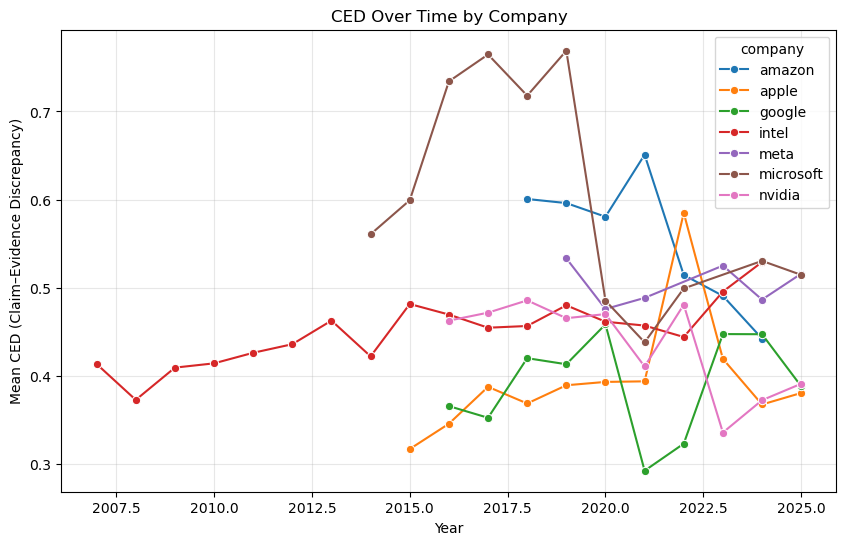

In [16]:
plt.figure(figsize=(10,6))
sns.lineplot(
    data=df,
    x="year", y="mean_CED_page",
    hue="company",
    marker="o"
)
plt.title("CED Over Time by Company")
plt.ylabel("Mean CED (Claim–Evidence Discrepancy)")
plt.xlabel("Year")
plt.grid(True, alpha=0.3)
plt.show()


CED Over Time by Company — Interpretation
This plot tracks how ESG-washing risk (CED) evolves across years for each company.

Key Insights
1. Microsoft shows consistently the highest CED (0.70–0.78)
Indicates many claims, limited evidence, and large claim–evidence distance.
A strong indicator of persistent ESG-washing tendencies from 2015–2020.
2. Amazon has moderately high CED with noticeable spikes (≈2020–2021)
These spikes correspond to years where Amazon reporting adopts a more PR-heavy, aspirational tone.
Suggests episodic ESG-washing, especially around climate commitments.
3. Meta fluctuates significantly year-to-year
Reveals inconsistent reporting quality.
Some years are evidence-balanced, others are claim-heavy with limited substantiation.
4. Apple, Google, Nvidia, and Intel cluster at lower CED levels (0.35–0.50)
Their reporting tends to be more evidence-supported and less promotional.
This cluster suggests more trustworthy and balanced ESG disclosure relative to Microsoft/Amazon

Interpretation Summary

High CED → many claims + insufficient evidence → high discrepancy → potential ESG-washing risk.
Low CED → stronger alignment between claims and evidence → lower discrepancy → more trustworthy reporting.

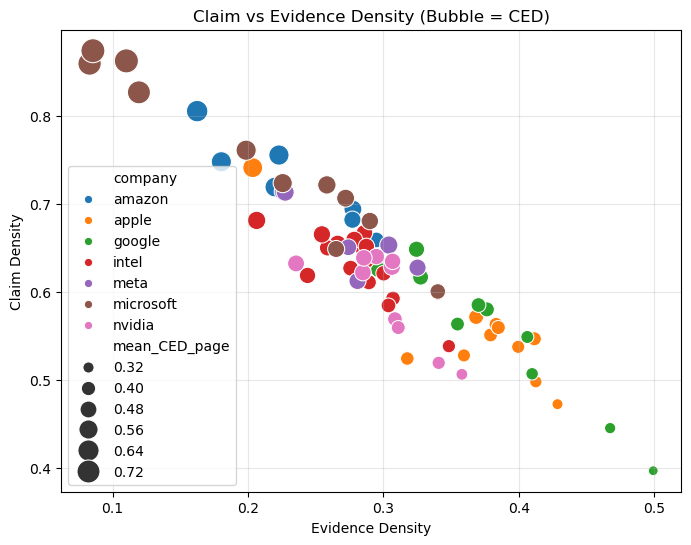

In [19]:
plt.figure(figsize=(8,6))
sns.scatterplot(
    data=df,
    x="mean_evidence_density",
    y="mean_claim_density",
    hue="company",
    size="mean_CED_page",
    sizes=(50, 300)
)
plt.title("Claim vs Evidence Density (Bubble = CED)")
plt.xlabel("Evidence Density")
plt.ylabel("Claim Density")
plt.grid(True, alpha=0.3)
plt.show()


**Interpretation of Claim vs. Evidence Density**

The Claim–Evidence Density plot reveals a clear inverse relationship between how frequently companies make sustainability claims and how much supporting evidence they provide. Companies positioned in the upper-left of the plot—most notably Microsoft—exhibit very high claim density but extremely low evidence density, resulting in the largest CED bubbles and signaling a heightened risk of ESG-washing. Amazon also shows a claim-heavy profile with only moderate evidence, yielding elevated discrepancy scores. In contrast, Apple and Google occupy the lower-right region, where higher evidence density is paired with more conservative claim-making, producing smaller bubbles and indicating more trustworthy, substantiated reporting. Intel, Meta, and NVIDIA fall in the mid-range cluster, suggesting mixed performance—neither strongly evidence-driven nor highly claim-inflated. Overall, the plot highlights that higher evidence density consistently correlates with lower discrepancy, while claim-heavy, evidence-light reporting corresponds to elevated ESG-washing risk.

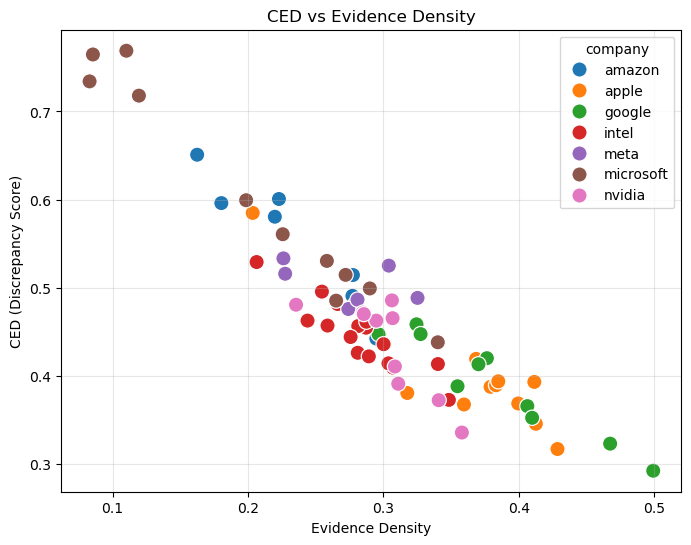

In [20]:
plt.figure(figsize=(8,6))
sns.scatterplot(
    data=df,
    x="mean_evidence_density",
    y="mean_CED_page",
    hue="company",
    marker="o",
    s=120
)
plt.title("CED vs Evidence Density")
plt.xlabel("Evidence Density")
plt.ylabel("CED (Discrepancy Score)")
plt.grid(True, alpha=0.3)
plt.show()
